**COU 07506 — Digital Signal Processing**

**Week 2 — Lab 1A: Sampling, Aliasing and Quantization**

**Name:** NASONI JOEL RICHARD

**Registration Number:** 240242468221

**Date:** 23/11/2021

**Group:** 03

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

Task 2.1 - Aliasing of a sinusoid

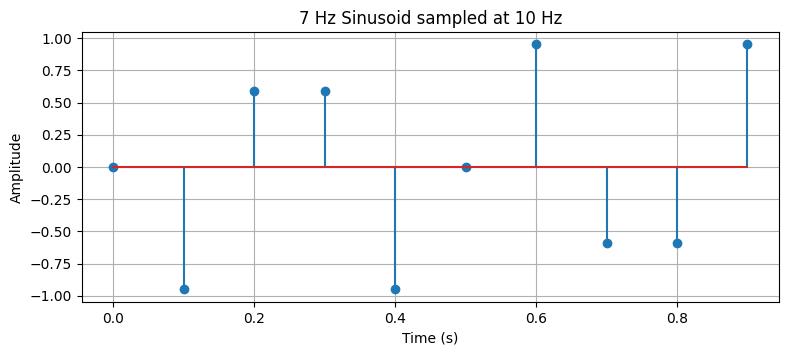

In [ ]:
fs = 10
f = 7

t = np.arange(0, 1, 1/fs)
x = np.sin(2*np.pi*f*t)

plt.stem(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("7 Hz Sinusoid sampled at 10 Hz")
plt.grid(True)
plt.show()

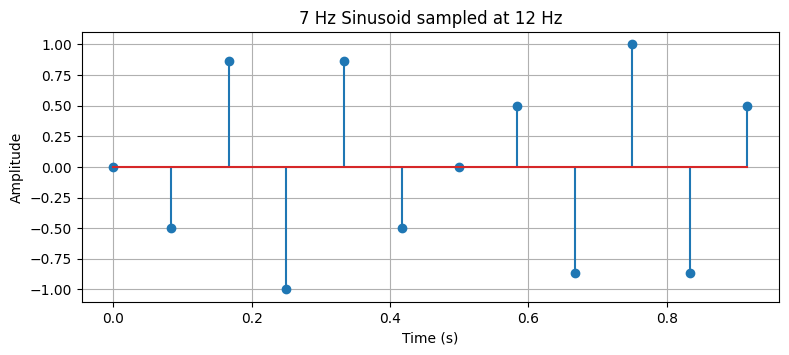

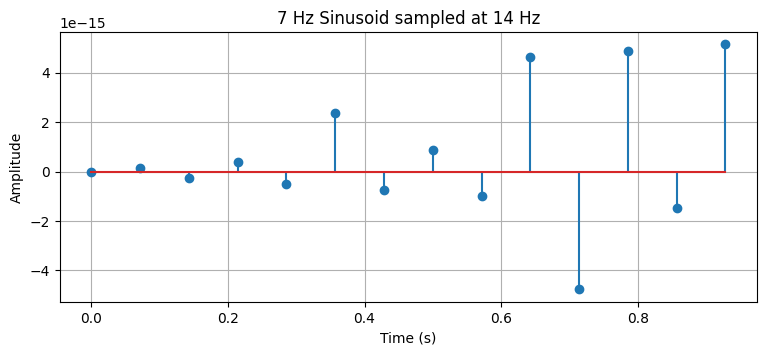

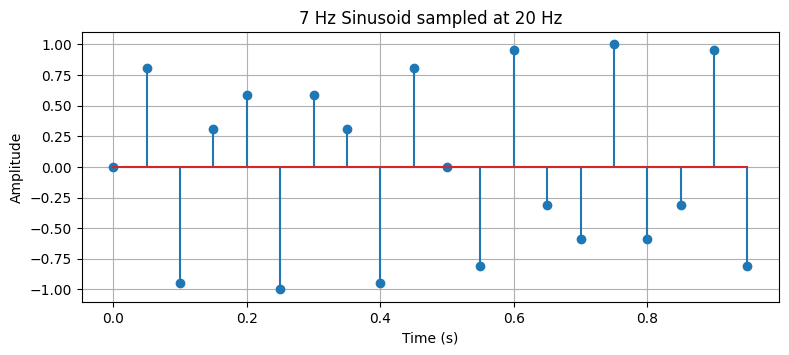

In [ ]:
fs_values = [12, 14, 20]
f = 7

for fs in fs_values:
    t = np.arange(0, 1, 1/fs)
    x = np.sin(2*np.pi*f*t)

    plt.figure()
    plt.stem(t, x)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.title(f"7 Hz Sinusoid sampled at {fs} Hz")
    plt.grid(True)
    plt.show()

**Observation:** Aliasing occurs when the sampling frequency is insufficient to represent the original signal correctly. The 7 Hz sinusoid sampled at 10 Hz appears as a 3 Hz sinusoid, while at 12 Hz it appears as 5 Hz. At sampling frequencies of 14 Hz and 20 Hz, the signal can be represented without aliasing according to the Nyquist criterion.

Task 2.2 - Hear Aliasing.

In [ ]:
fs = 8000
duration = 1.0

t = np.arange(0, duration, 1/fs)
x = np.sin(2*np.pi*500*t) + 0.5*np.sin(2*np.pi*3000*t)

In [ ]:
k = 2

x_down = x[::k]
fs_down = fs/k

print("Original sampling rate:", fs)
print("New sampling rate:", fs_down)

Original sampling rate: 8000
New sampling rate: 4000.0


Task 2.2 - Downsampling with anti-aliasing filter.

In [ ]:
x_decimated = signal.decimate(x, 2)

fs_decimated = fs/2

print("Original sampling rate:", fs)
print("New sampling rate:", fs_decimated)

Original sampling rate: 8000
New sampling rate: 4000.0


In [ ]:
for k in [2, 4, 8]:

    x_down = x[::k]
    x_decimated = signal.decimate(x, k)

    print("k =", k)
    print("Original samples:", len(x))
    print("Without filtering:", len(x_down))
    print("With filtering:", len(x_decimated))
    print("----------------------")

k = 2
Original samples: 8000
Without filtering: 4000
With filtering: 4000
----------------------
k = 4
Original samples: 8000
Without filtering: 2000
With filtering: 2000
----------------------
k = 8
Original samples: 8000
Without filtering: 1000
With filtering: 1000
----------------------


**Observation:**

Downsampling without filtering can introduce aliasing because high-frequency components are not removed before reducing the sampling rate. Downsampling with `signal.decimate()` applies an anti-aliasing filter before reducing the samples.

For k = 8, the filtered signal has fewer unwanted high-frequency components compared to the unfiltered signal.

Task 2.3 — A Uniform Quantizer

In [ ]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

In [ ]:
fs = 8000
t = np.arange(0, 0.01, 1/fs)

x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)

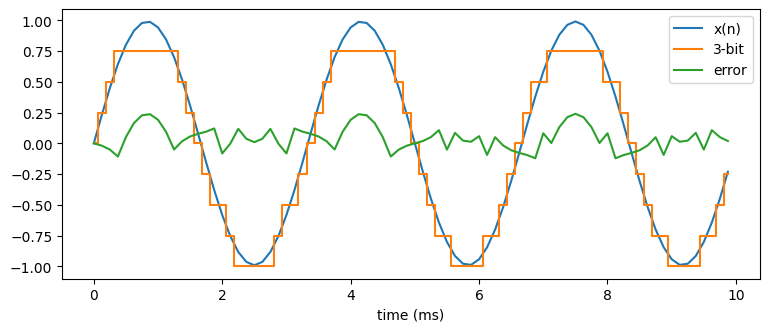

In [ ]:
plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")

plt.xlabel("time (ms)")
plt.legend()
plt.show()

**Observation:**

The original sinusoidal signal is continuous in amplitude, while the quantized signal has discrete amplitude levels. The difference between the original signal and the quantized signal represents quantization error.

Task 2.4 — Verify the 6 dB per bit rule

In [ ]:
bits_list = [2, 4, 6, 8, 10, 12, 14, 16]
sqnr_measured = []

In [ ]:
for B in bits_list:
    xq = quantize(x, B)
    error = x - xq

    sqnr = 10*np.log10(
        np.mean(x**2)/np.mean(error**2)
    )

    sqnr_measured.append(sqnr)

In [ ]:
sqnr_theoretical = 6.02*np.array(bits_list) + 1.76

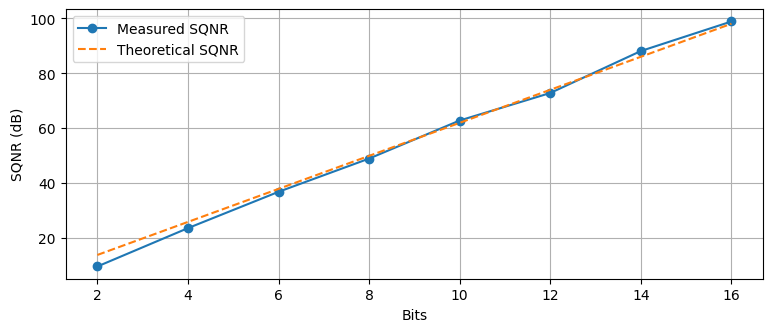

In [ ]:
plt.plot(bits_list, sqnr_measured, 'o-', label="Measured SQNR")
plt.plot(bits_list, sqnr_theoretical, '--', label="Theoretical SQNR")

plt.xlabel("Bits")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid(True)
plt.show()

**Observation:**

The graph shows that SQNR increases as the number of quantization bits increases. The measured SQNR generally follows the theoretical SQNR. Approximately 6 dB improvement in SQNR is obtained for every additional bit. This means that increasing the number of bits reduces quantization error and improves signal quality.

Task 2.5 — Quantize Voice

In [47]:
fs, voice = wavfile.read("my_voice.wav")

print("Sampling frequency:", fs)
print("Audio shape:", voice.shape)
print("Data type:", voice.dtype)

Sampling frequency: 44100
Audio shape: (85540, 2)
Data type: int16


In [48]:
voice_float = voice.astype(np.float64)

voice_mono = voice_float.mean(axis=1)

voice_mono = voice_mono / 32768.0

print("Voice shape:", voice_mono.shape)
print("Minimum value:", np.min(voice_mono))
print("Maximum value:", np.max(voice_mono))

Voice shape: (85540,)
Minimum value: -0.217864990234375
Maximum value: 0.229736328125


In [49]:
bits_list = [4, 8, 12]

voice_quantized = {}

for B in bits_list:
    voice_quantized[B] = quantize(voice_mono, B)
    print(f"{B}-bit quantization completed")

4-bit quantization completed
8-bit quantization completed
12-bit quantization completed


In [50]:
from IPython.display import Audio, display

print("Original voice:")
display(Audio(voice_mono, rate=fs))

print("4-bit quantized voice:")
display(Audio(voice_quantized[4], rate=fs))

print("8-bit quantized voice:")
display(Audio(voice_quantized[8], rate=fs))

print("12-bit quantized voice:")
display(Audio(voice_quantized[12], rate=fs))

Original voice:


4-bit quantized voice:


8-bit quantized voice:


12-bit quantized voice:


In [51]:
for B in [4, 8, 12]:
    error = voice_mono - voice_quantized[B]

    sqnr = 10 * np.log10(
        np.mean(voice_mono**2) / np.mean(error**2)
    )

    print(f"{B}-bit SQNR: {sqnr:.2f} dB")

4-bit SQNR: 5.53 dB
8-bit SQNR: 27.82 dB
12-bit SQNR: 50.34 dB


**Observation**

The results show that SQNR increases as the number of quantization bits increases. The 4-bit quantized signal has an SQNR of 5.53 dB, the 8-bit signal has 27.82 dB, and the 12-bit signal has 50.34 dB.

This indicates that increasing the number of quantization bits reduces quantization error and improves the quality of the reconstructed audio signal.

**Analysis Questions**

**Question 1**

When a 7 Hz signal is sampled at 10 Hz, aliasing occurs because the sampling frequency is below twice the signal frequency. The sampled signal appears at an alias frequency of:

f_alias = |7 - 10| = 3 Hz.

Therefore, the 7 Hz tone appears as a 3 Hz tone in the sampled signal.

**Question 2**

Aliasing cannot be removed after naïve downsampling because high-frequency components have already been folded into lower frequencies during sampling. Once this happens, the original frequency information is lost, making it impossible to separate the aliased components from the original low-frequency components.

**Question 3**

The SQNR increases by approximately 6.02 dB for every additional quantization bit.

My measurements show an increase of 22.29 dB from 4-bit to 8-bit and 22.52 dB from 8-bit to 12-bit. Dividing these values by four gives approximately 5.57 dB and 5.63 dB per bit. Therefore, my measurements are close to the theoretical value of 6.02 dB per bit.

**Question 4**

A suitable sampling rate is 10 Hz because the sensor changes by at most 0.1 °C per second. Sampling every 0.1 seconds limits the maximum temperature change between samples to 0.01 °C.

For quantization, the temperature range is 100 °C and the required resolution is 0.01 °C. Therefore:

Number of levels = 100 / 0.01 = 10,000.

Since 2^13 = 8192 and 2^14 = 16384, 14 bits are required.

Therefore, I suggest a sampling rate of 10 Hz and a quantization resolution of 14 bits.